# بهبود کد کلاسی: عامل جاروبرقی با حسگر نویزی + ارتباط با پروژه تشخیص اعداد دست نویس

چالش انتخاب شده از بین چهار چالش مطرح شده در کلاس: **حسگر نویزی (نویز دار بودن حسگر)**

دلیل انتخاب: موضوع پروژه من تشخیص اعداد دست نویس است. در این پروژه «حسگر» همان تصویر ورودی است و اگر تصویر نویز داشته باشد یا کیفیتش پایین باشد، عامل باید بتواند درست تصمیم بگیرد. پس اول همین ایده را روی تمرین جاروبرقی کلاس تست می کنم (حسگر کثیفی که گاهی اشتباه می گوید) و بعد همان ایده را روی دیتاست ارقام پیاده می کنم.


## بخش ۱: کد کلاس جاروبرقی (نسخه اصلی کلاس)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROOMS = 4
STEPS = 50
RUNS = 100

In [3]:
# این همون تابع simulate کلاس هست (بدون تغییر)
def simulate(agent, seed):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += int((~dirt).sum())
    return int(score)

## بخش ۲: تغییر اصلی — اضافه کردن نویز به حسگر کثیفی

در کد کلاس عامل همیشه وضعیت واقعی اتاق را می بیند (`dirt[pos]`). برای شبیه سازی حسگر نویزی یک تابع جدید می نویسم که با احتمال `sensor_error` وضعیتی که حسگر گزارش می کند برعکس می شود؛ یعنی عامل گاهی فکر می کند اتاق کثیف است ولی در واقع تمیز است (یا برعکس).

سوال اصلی این بخش: **امتیاز عامل model وقتی حسگر نویز دارد چقدر افت می کند؟**

In [4]:
# نسخه جدید simulate با پارامتر sensor_error
# sensor_error = احتمال اینکه حسگر کثیفی وضعیت اشتباه گزارش کند (0 یعنی حسگر کامل)
def simulate_noisy(agent, seed, sensor_error=0.0):
    rng = np.random.default_rng(seed)
    dirt = rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0

    for step in range(STEPS):
        # حسگر نویزی: با احتمال sensor_error چیزی که عامل می بیند برعکس است
        perceived = bool(dirt[pos])
        if rng.random() < sensor_error:
            perceived = not perceived
        known_clean[pos] = not perceived

        if agent == "random":
            action = rng.choice(["Left", "Right", "Suck"])
        elif perceived:                      # عامل فقط چیزی که حسگر می گوید را می بیند
            action = "Suck"
        elif agent == "reflex":
            action = rng.choice(["Left", "Right"])
        elif known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            if pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        if action == "Suck":
            dirt[pos] = False                # حتی اگر حسگر اشتباه گفته بود، Suck بی ضرر است
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        score += int((~dirt).sum())
    return int(score)

# چک سریع که کار می کند
print("بدون نویز:  ", simulate_noisy("model", seed=1, sensor_error=0.0))
print("با نویز 10%:", simulate_noisy("model", seed=1, sensor_error=0.1))
print("با نویز 30%:", simulate_noisy("model", seed=1, sensor_error=0.3))

بدون نویز:   198
با نویز 10%: 198
با نویز 30%: 198


## بخش ۳: مقایسه امتیاز در سطوح مختلف نویز (۱۰۰ اجرا مثل کلاس)

In [5]:
errors = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]

rows = []
for e in errors:
    for seed in range(RUNS):
        rows.append({"sensor_error": e, "seed": seed,
                     "score": simulate_noisy("model", seed, e)})

df = pd.DataFrame(rows)
summary = df.groupby("sensor_error")["score"].agg(["mean", "std"]).round(1)
print(summary)

               mean   std
sensor_error             
0.00          195.7   2.9
0.05          191.8  15.6
0.10          187.3  21.2
0.20          180.2  26.1
0.30          176.0  27.9
0.50          163.2  33.3


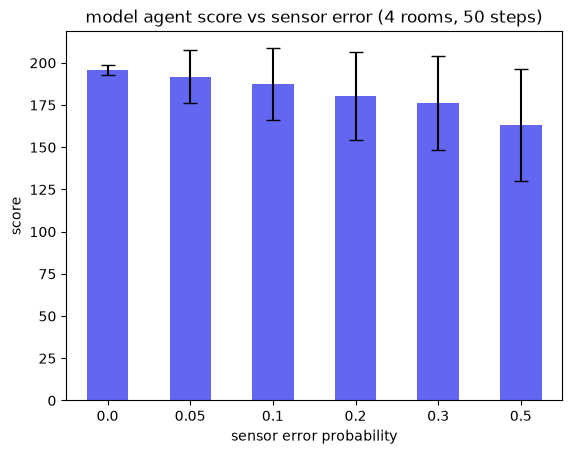

In [6]:
summary["mean"].plot(kind="bar", yerr=summary["std"], capsize=5, color="#6366f1")
plt.title("model agent score vs sensor error (4 rooms, 50 steps)")
plt.xlabel("sensor error probability")
plt.ylabel("score")
plt.xticks(rotation=0)
plt.show()

نتیجه قابل پیش بینی بود: هرچه نویز حسگر بیشتر می شود، عامل وقتش را با Suck زدن روی اتاق های تمیز یا حرکت اشتباه هدر می دهد و امتیازش می افتد. البته سقوط آنقدر شدید نیست چون Suck زدن روی اتاق تمیز صدمه ای نمی زند، فقط یک قدم تلف می شود.

## بخش ۴: انتقال همین ایده به پروژه من (تشخیص اعداد دست نویس)

در پروژه من «حسگر» همان تصویر ورودی است. الان دقیقا همان آزمایش بالا را روی دیتاست ارقام scikit-learn انجام می دهم:
1. یک مدل ساده آموزش می دهم (KNN چون ساده ترین چیزی است که تا حالا دیدم)
2. به تصاویر تست نویز اضافه می کنم (مثل کاری که با حسگر جاروبرقی کردم)
3. می سنجم دقت مدل در سطوح مختلف نویز چقدر افت می کند

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

digits = load_digits()
X, y = digits.data, digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

print("دقت روی داده تمیز:", accuracy_score(y_test, model.predict(X_test)))

دقت روی داده تمیز: 0.9933333333333333


### اضافه کردن نویز به تصاویر تست

پیکسل های دیتاست digits بین 0 تا 16 هستند. نویز را به شکل یک عدد تصادفی به پیکسل ها اضافه می کنم (مقدار نویز را با ضریب noise_level کنترل می کنم). این شبیه سازی این است که تصویر ورودی کیفیت پایین تری دارد — یعنی همان «حسگر نویزی» ولی این بار برای پروژه خودم.

In [8]:
def add_noise(images, noise_level, seed=0):
    rng = np.random.default_rng(seed)
    noise = rng.uniform(-noise_level, noise_level, images.shape)
    noisy = np.clip(images + noise, 0, 16)   # پیکسل ها باید بین 0 و 16 بمانند
    return noisy

levels = [0, 1, 2, 3, 4, 6, 8]
results = []
for lv in levels:
    accs = []
    for s in range(10):   # 10 بار با seed های مختلف تا نتیجه تصادفی نباشد
        X_noisy = add_noise(X_test, lv, seed=s)
        accs.append(accuracy_score(y_test, model.predict(X_noisy)))
    results.append({"noise_level": lv, "accuracy": np.mean(accs)})
    print(f"noise={lv}  ->  accuracy={np.mean(accs):.3f}")

res = pd.DataFrame(results)
print(res.round(3))

noise=0  ->  accuracy=0.993
noise=1  ->  accuracy=0.992
noise=2  ->  accuracy=0.989
noise=3  ->  accuracy=0.988
noise=4  ->  accuracy=0.986
noise=6  ->  accuracy=0.977
noise=8  ->  accuracy=0.956
   noise_level  accuracy
0            0     0.993
1            1     0.992
2            2     0.989
3            3     0.988
4            4     0.986
5            6     0.977
6            8     0.956


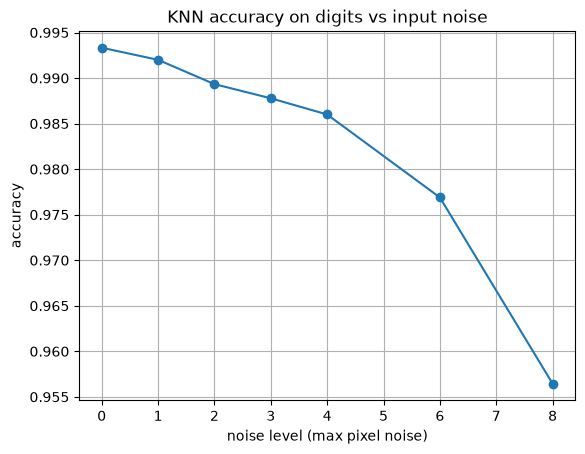

In [9]:
plt.plot(res["noise_level"], res["accuracy"], marker="o")
plt.title("KNN accuracy on digits vs input noise")
plt.xlabel("noise level (max pixel noise)")
plt.ylabel("accuracy")
plt.grid(True)
plt.show()

### دیدن چند نمونه نویزی

برای اینکه ملموس شود چند نمونه از یک تصویر تست را با نویزهای متفاوت می کشم:

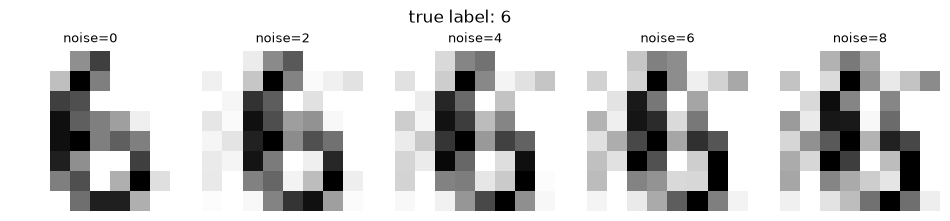

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(12, 2.5))
test_img = X_test[0]
for ax, lv in zip(axes, [0, 2, 4, 6, 8]):
    img = add_noise(test_img.reshape(1, -1), lv, seed=3).reshape(8, 8)
    ax.imshow(img, cmap="gray_r")
    ax.set_title(f"noise={lv}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"true label: {y_test[0]}")
plt.show()

## جمع بندی و تحلیل

- در تمرین جاروبرقی دیدیم که نویز حسگر باعث هدر رفتن قدم های عامل می شود ولی چون عمل Suck بی ضرر است، افت امتیاز تدریجی بود.
- در پروژه تشخیص ارقام هم دیدیم که با زیاد شدن نویز تصویر ورودی، دقت KNN افت می کند. نکته این بود که تا نویزهای متوسط مدل نسبتا مقاوم بود چون KNN از 64 پیکسل با هم رأی می گیرد و نویز روی همه پیکسل ها یکسان نیست.
- رابطه دو بخش: در هر دو مورد «عامل» تصمیمش را بر اساس یک ورودی ناقص می گیرد. تفاوت این است که در جاروبرقی عامل می تواند در قدم بعدی دوباره حس بگیرد ولی مدل تشخیص ارقام فقط یک فرصت دارد، برای همین در گام های بعدی پروژه بهتر است سراغ روش های مقاوم سازی مثل پیش پردازش تصویر بروم تا افت دقت کمتر شود.

## سوالات تحلیلی
1. چرا عامل model در تمرین جاروبرقی با نویز زیاد باز هم کاملا از کار نمی افتد؟ (چون Suck روی اتاق تمیز هیچ ضرری ندارد و فقط یک قدم تلف می شود)
2. اگر به جای KNN از یک مدل حساس تر استفاده می شد، افت دقت بیشتر بود یا کمتر؟ (حدسم اولیه: بیشتر، چون KNN با رأی گیری از همسایه ها کمی مقاوم است — در گام های بعدی پروژه می توان تست کرد)
3. چه روشی می تواند قبل از پیش بینی، اثر نویز را کم کند؟